In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_train = pd.read_csv("/work/train_v9rqX0R.csv")
df_test = pd.read_csv("/work/test_AbJTz2l.csv")
df_train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


In [3]:
print("df_train", df_train.shape)
print("df_test", df_test.shape)

df_train (8523, 12)
df_test (5681, 11)


In [4]:
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIn

In [5]:
df_train.describe()

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.857645,0.066132,140.992782,1997.831867,2181.288914
std,4.643456,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.773750,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [6]:
# Missing values
print("Train:\n", df_train.isnull().sum())
print("\nTest:\n", df_test.isnull().sum())
miss_train = df_train.isnull().sum()
miss_train2 = (miss_train / len(df_train)) * 100
print("Train:\n", miss_train2)
miss_test = df_test.isnull().sum()
miss_test2 = (miss_test / len(df_test)) * 100
print("\nTest:\n", miss_test2)

Train:
 Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Test:
 Item_Identifier                 0
Item_Weight                   976
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1606
Outlet_Location_Type            0
Outlet_Type                     0
dtype: int64
Train:
 Item_Identifier               0.000000
Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               0.000000
Item_Type   

In [7]:
# Check whether missing outlet sizes vary by outlet type.
print(df_train[df_train['Outlet_Size'].isna()]['Outlet_Type'].value_counts())
print(df_train['Item_Weight'].describe())

Outlet_Type
Supermarket Type1    1855
Grocery Store         555
Name: count, dtype: int64
count    7060.000000
mean       12.857645
std         4.643456
min         4.555000
25%         8.773750
50%        12.600000
75%        16.850000
max        21.350000
Name: Item_Weight, dtype: float64


In [8]:
#Imputation (EDA-facing) — Median imputation for Item_Weight
item_weight_map = df_train.groupby('Item_Identifier')['Item_Weight'].median()
type_weight_map = df_train.groupby('Item_Type')['Item_Weight'].median() 
for df in [df_train, df_test]:
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Identifier'].map(item_weight_map))
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Type'].map(type_weight_map))

In [9]:
# Fill outlet size from the most common size for each outlet type.
mode_size = df_train.groupby('Outlet_Type')['Outlet_Size'].agg(
    lambda x: x.mode().iloc[0] if not x.mode().empty else 'Unknown'
)
df_train['Outlet_Size_Missing'] = df_train['Outlet_Size'].isna().astype(int)
df_test['Outlet_Size_Missing'] = df_test['Outlet_Size'].isna().astype(int)

df_train['Outlet_Size'] = df_train['Outlet_Size'].fillna(
    df_train['Outlet_Type'].map(mode_size)
)
df_test['Outlet_Size'] = df_test['Outlet_Size'].fillna(
    df_test['Outlet_Type'].map(mode_size)
)

In [10]:
print("Train:\n", df_train.isnull().sum())
print("\nTest:\n", df_test.isnull().sum())

Train:
 Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
Outlet_Size_Missing          0
dtype: int64

Test:
 Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Outlet_Size_Missing          0
dtype: int64


In [11]:
# Keep outlet IDs for later model diagnostics.
outlet_tr = df_train['Outlet_Identifier'].values.copy()
outlet_te = df_test['Outlet_Identifier'].values.copy()

In [12]:
target_col = "Item_Outlet_Sales"
cat_col = ["Item_Fat_Content", "Item_Type", "Outlet_Identifier", "Outlet_Size", "Outlet_Location_Type", "Outlet_Type"]
dis_col = ['Outlet_Establishment_Year']
num_cols = ['Item_Weight', 'Item_Visibility', 'Item_MRP']

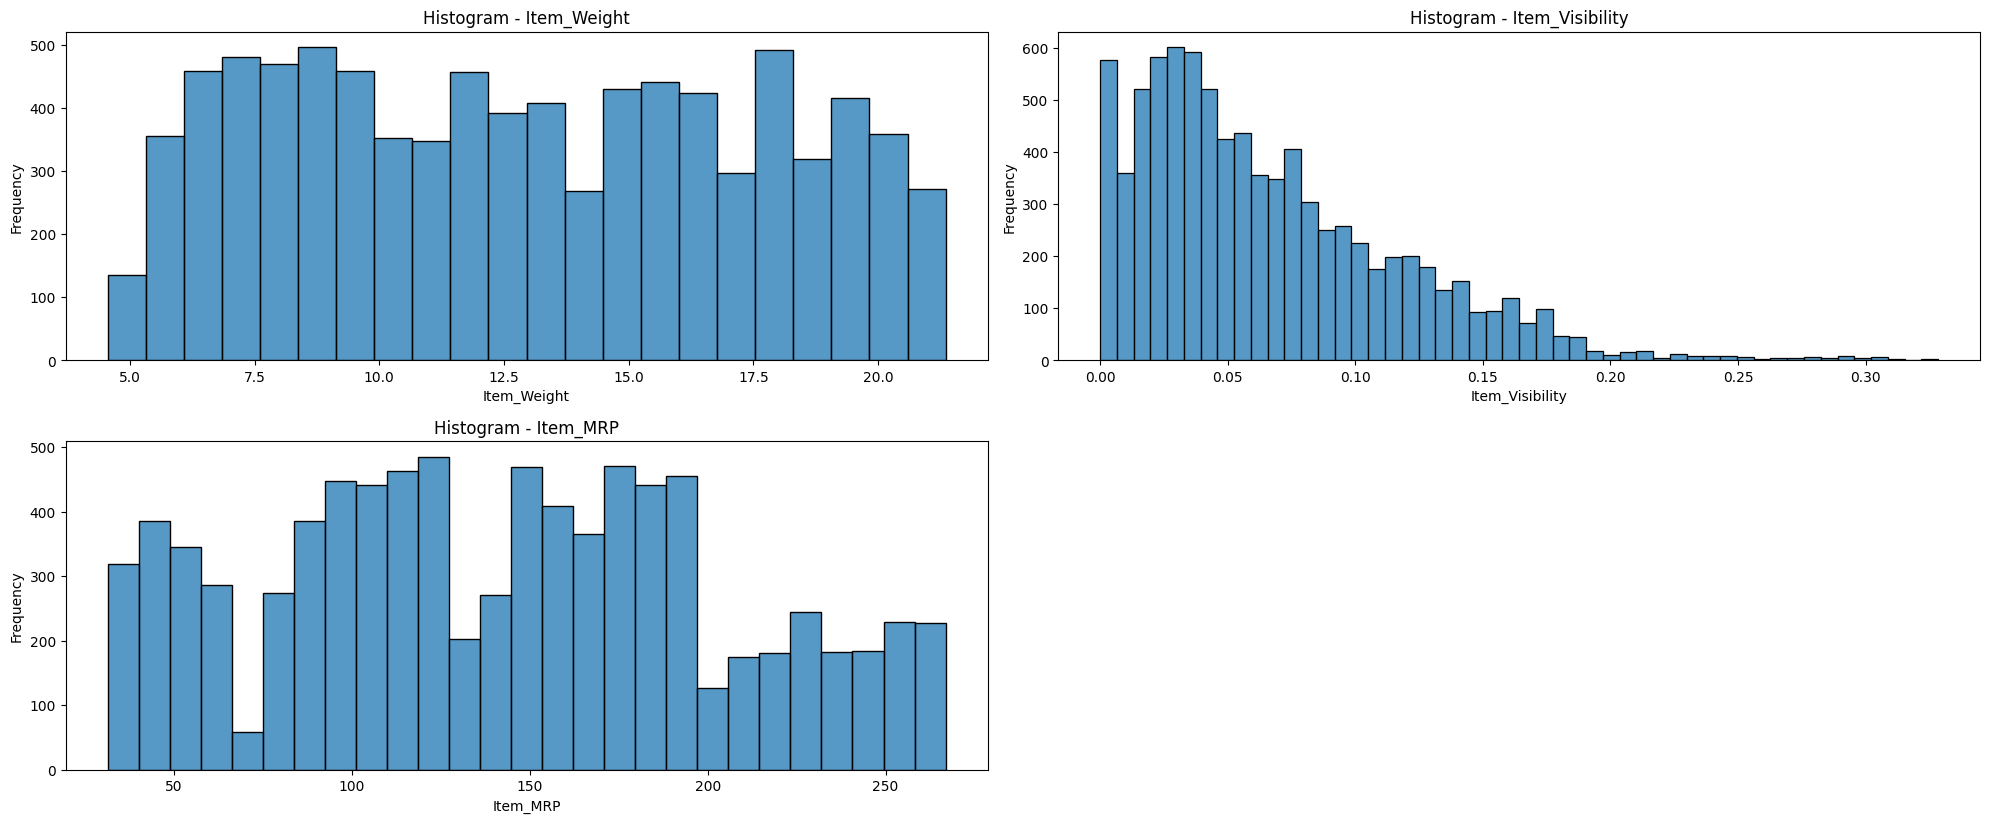

In [13]:
# Univariate analysis for Item_MRP, Item_Weight, Item_Visibility
plt.figure(figsize=(20, 12))
for i, col in enumerate(num_cols):
    plt.subplot(3, 2, i + 1)
    sns.histplot(df_train[col])
    plt.title(f'Histogram - {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Zeros: 526
Above 0.2: 134
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


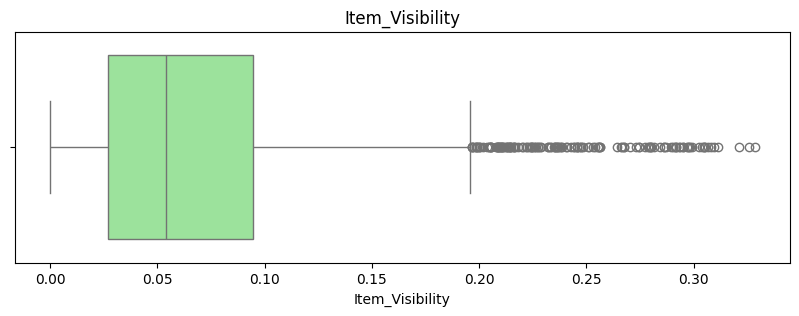

In [14]:
# Item visibility x zero count
print("Zeros:", (df_train['Item_Visibility'] == 0).sum())
print("Above 0.2:", (df_train['Item_Visibility'] > 0.2).sum())
plt.figure(figsize=(10, 3))
sns.boxplot(x=df_train['Item_Visibility'], color='lightgreen')
plt.title('Item_Visibility')
plt.show()

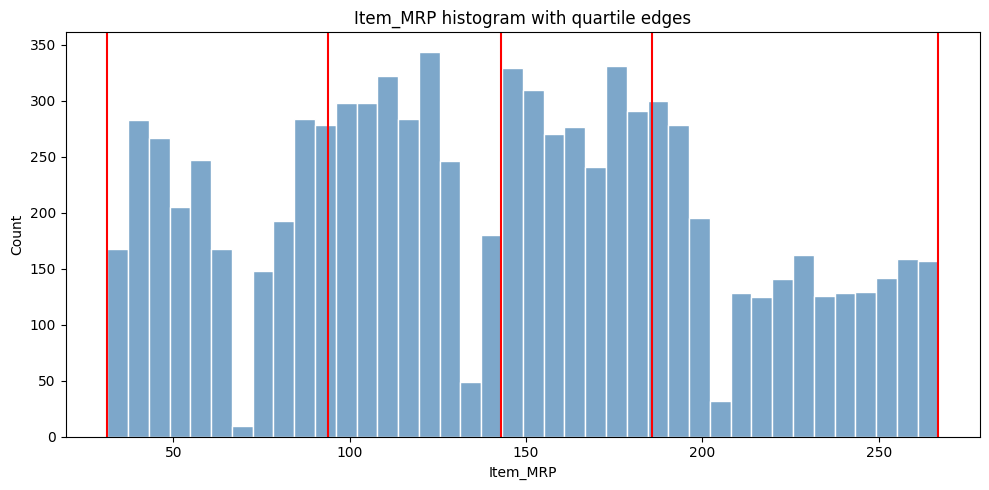

In [15]:
# histograms with quartile edges marked to show bin edges for mrp
_, edges = pd.qcut(df_train['Item_MRP'], q=4, retbins=True)
plt.figure(figsize=(10, 5))
sns.histplot(df_train['Item_MRP'], bins=40, color='steelblue',
             edgecolor='white', alpha=0.7)
for e in edges:
    plt.axvline(e, color='red', linewidth=1.5)
plt.title('Item_MRP histogram with quartile edges')
plt.xlabel('Item_MRP')
plt.tight_layout()
plt.show()

Outlet_Establishment_Year
1985    1463
1987     932
1997     930
1998     555
1999     930
2002     929
2004     930
2007     926
2009     928
Name: count, dtype: int64


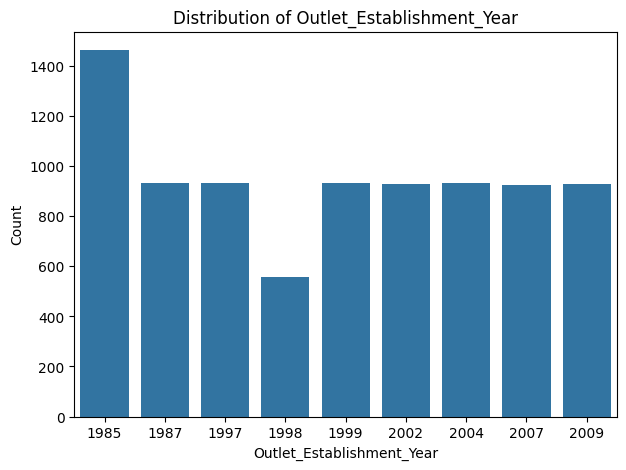

In [16]:
# Outlet establishment years
print(df_train['Outlet_Establishment_Year'].value_counts().sort_index())
plt.figure(figsize=(7, 5))
sns.countplot(data=df_train, x='Outlet_Establishment_Year')
plt.title('Distribution of Outlet_Establishment_Year')
plt.xlabel('Outlet_Establishment_Year')
plt.ylabel('Count')
plt.show()

In [17]:
# Category counts and percentages
for col in cat_col:
    print(f"Column: {col}")
    print(df_train[col].value_counts())
    print()
    print(df_train[col].value_counts(normalize=True) * 100)
    print()

Column: Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Item_Fat_Content
Low Fat    59.709023
Regular    33.896515
LF          3.707615
reg         1.372756
low fat     1.314091
Name: proportion, dtype: float64

Column: Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Item_Type
Fruits and Vegetables    14.455004
Snack Foods              14.079549
Household                10.676992
Frozen Foods             10.043412
Dairy     

In [18]:
# Standardize inconsistent category labels.
df_train['Item_Fat_Content'] = df_train['Item_Fat_Content'].replace({
    'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'
})
df_test['Item_Fat_Content'] = df_test['Item_Fat_Content'].replace({
    'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'
})
print("Train:")
print(df_train['Item_Fat_Content'].value_counts())
print("\nTest:")
print(df_test['Item_Fat_Content'].value_counts())

Train:
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64

Test:
Item_Fat_Content
Low Fat    3668
Regular    2013
Name: count, dtype: int64


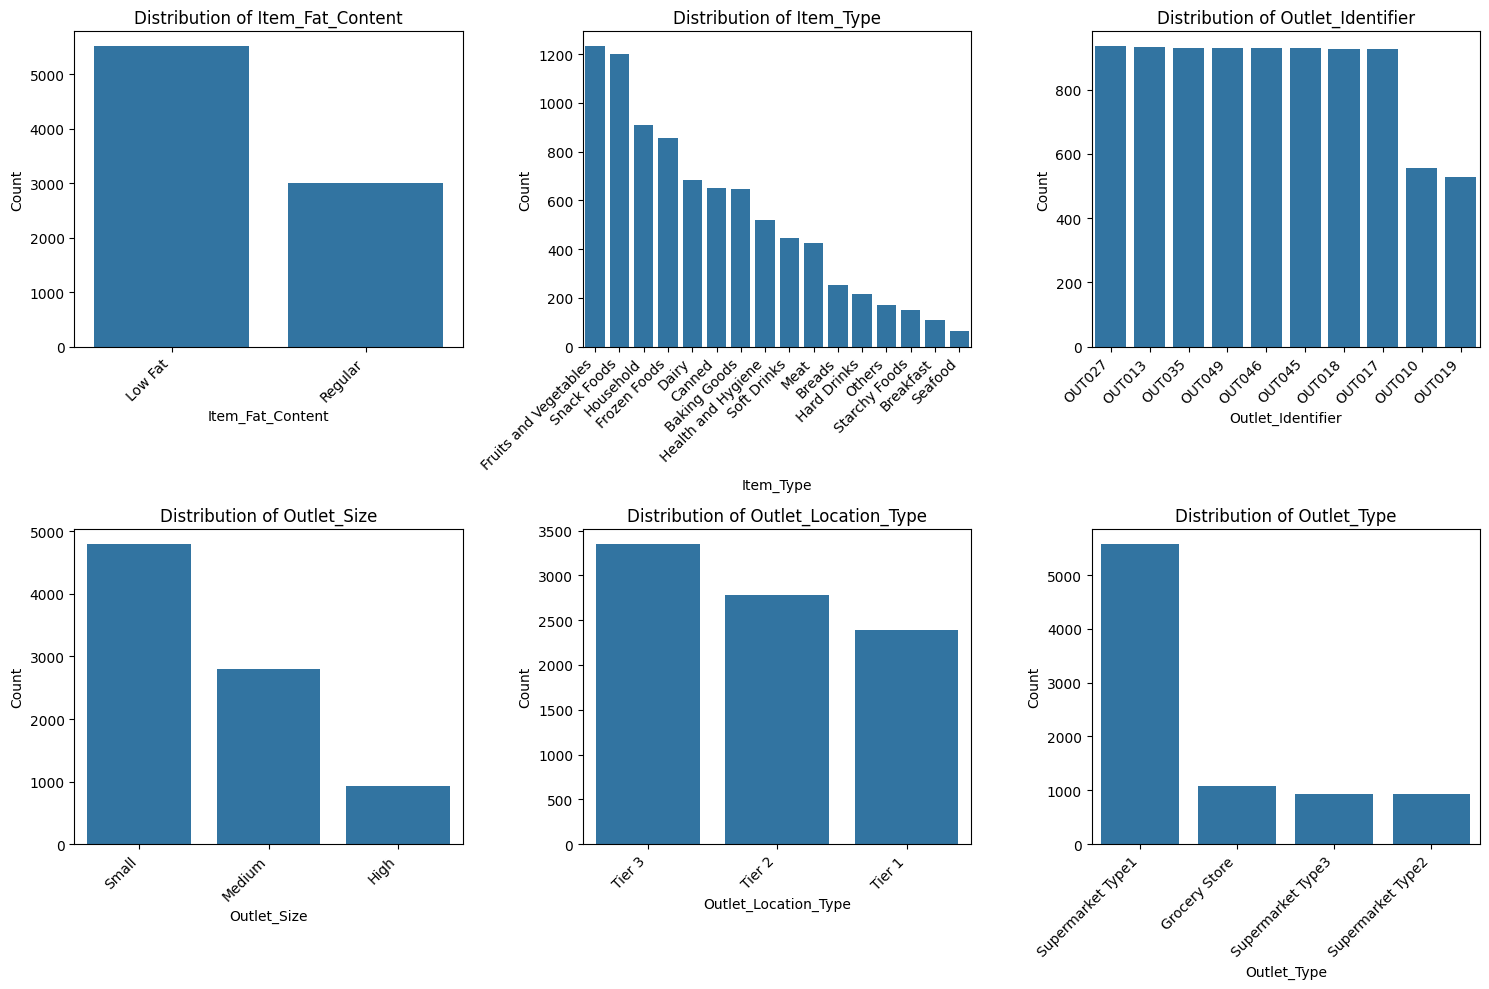

In [19]:
# Comparing category distributions
plt.figure(figsize=(15, 10))
for i, col in enumerate(cat_col, start=1):
    plt.subplot(2, 3, i)
    sns.countplot(data=df_train, x=col, order=df_train[col].value_counts().index)
    plt.title(f'Distribution of {col}', fontsize=12)
    plt.xlabel(col, fontsize=10)
    plt.ylabel('Count', fontsize=10)
    plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


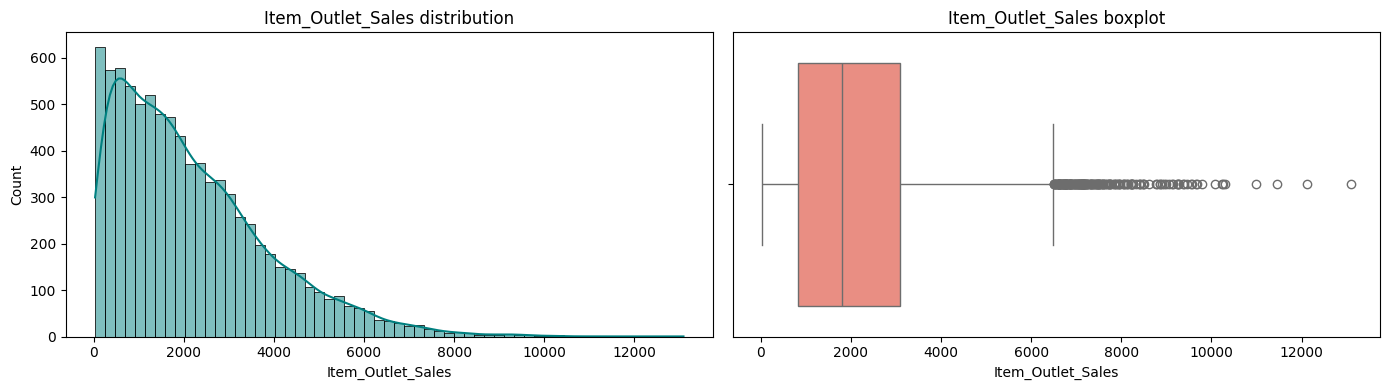

count     8523.000000
mean      2181.288914
std       1706.499616
min         33.290000
25%        834.247400
50%       1794.331000
75%       3101.296400
max      13086.964800
Name: Item_Outlet_Sales, dtype: float64
Skew: 1.1775306028542798


In [20]:
# Item_Outlet_Sales distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df_train['Item_Outlet_Sales'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Item_Outlet_Sales distribution')
sns.boxplot(x=df_train['Item_Outlet_Sales'], ax=axes[1], color='salmon')
axes[1].set_title('Item_Outlet_Sales boxplot')
plt.tight_layout()
plt.show()
print(df_train['Item_Outlet_Sales'].describe())
print("Skew:", df_train['Item_Outlet_Sales'].skew())

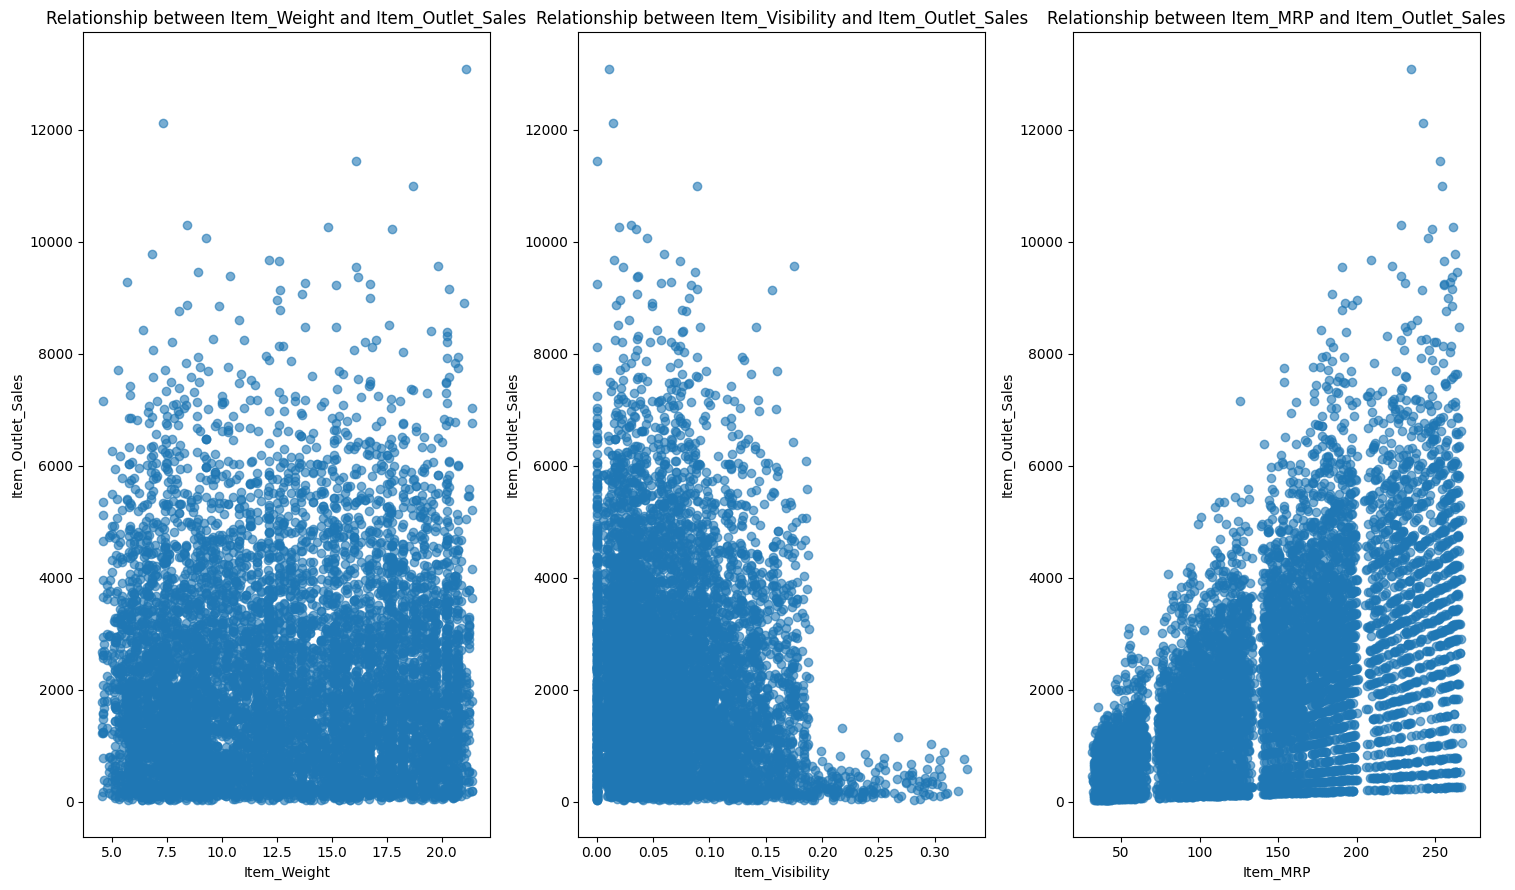

In [21]:
# Bivariate analysis
plt.figure(figsize=(15,9))
for i, col in enumerate(num_cols,1): 
        plt.subplot(1,3,i)
        plt.scatter(df_train[col], df_train[target_col],alpha=0.6)
        plt.xlabel(col)
        plt.ylabel(target_col)
        plt.title(f"Relationship between {col} and {target_col}")
plt.tight_layout()
plt.show()

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


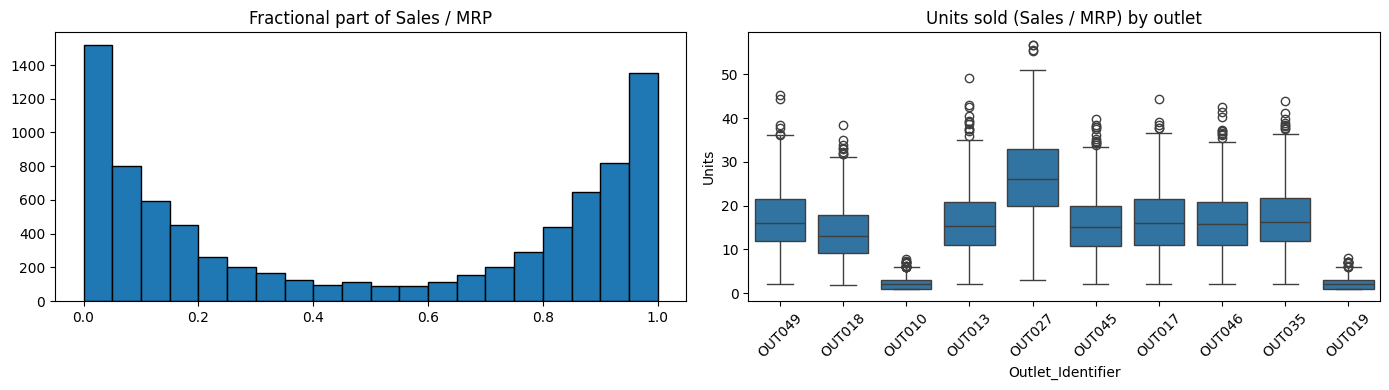

In [22]:
# Units will be how many items were sold 
# use this for EDA only, do not include in test
df_train['Units'] = df_train['Item_Outlet_Sales'] / df_train['Item_MRP']
frac = df_train['Units'] % 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(frac, bins=20, edgecolor='black')
axes[0].set_title('Fractional part of Sales / MRP')

sns.boxplot(data=df_train, x='Outlet_Identifier', y='Units', ax=axes[1])
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title('Units sold (Sales / MRP) by outlet')

plt.tight_layout()
plt.show()

In [39]:
df_train.groupby('Outlet_Identifier')['Units'].agg(['mean', 'std', 'min', 'max']).round(2)

,mean,std,min,max
Outlet_Identifier,,,,
OUT010,2.38,1.38,0.96,7.76
OUT013,16.00,7.27,1.95,49.16
OUT017,16.66,7.21,1.97,44.48
OUT018,13.85,6.45,1.94,38.35
OUT019,2.44,1.40,0.95,7.91
OUT027,26.61,9.50,3.00,56.84
OUT035,16.97,7.31,1.97,44.00
OUT045,15.58,6.95,1.98,39.89
OUT046,16.19,7.22,1.99,42.50


/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


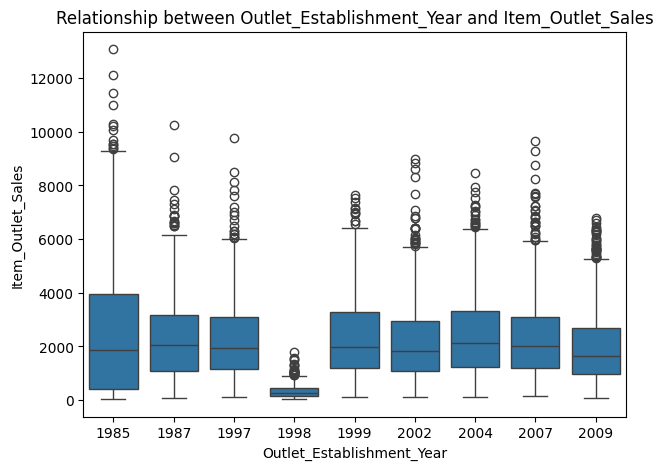

In [23]:
# Outlet establishment year versus sales
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_train, x='Outlet_Establishment_Year', y='Item_Outlet_Sales')
plt.title('Relationship between Outlet_Establishment_Year and Item_Outlet_Sales')
plt.xlabel('Outlet_Establishment_Year')
plt.ylabel('Item_Outlet_Sales')
plt.show()

/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.

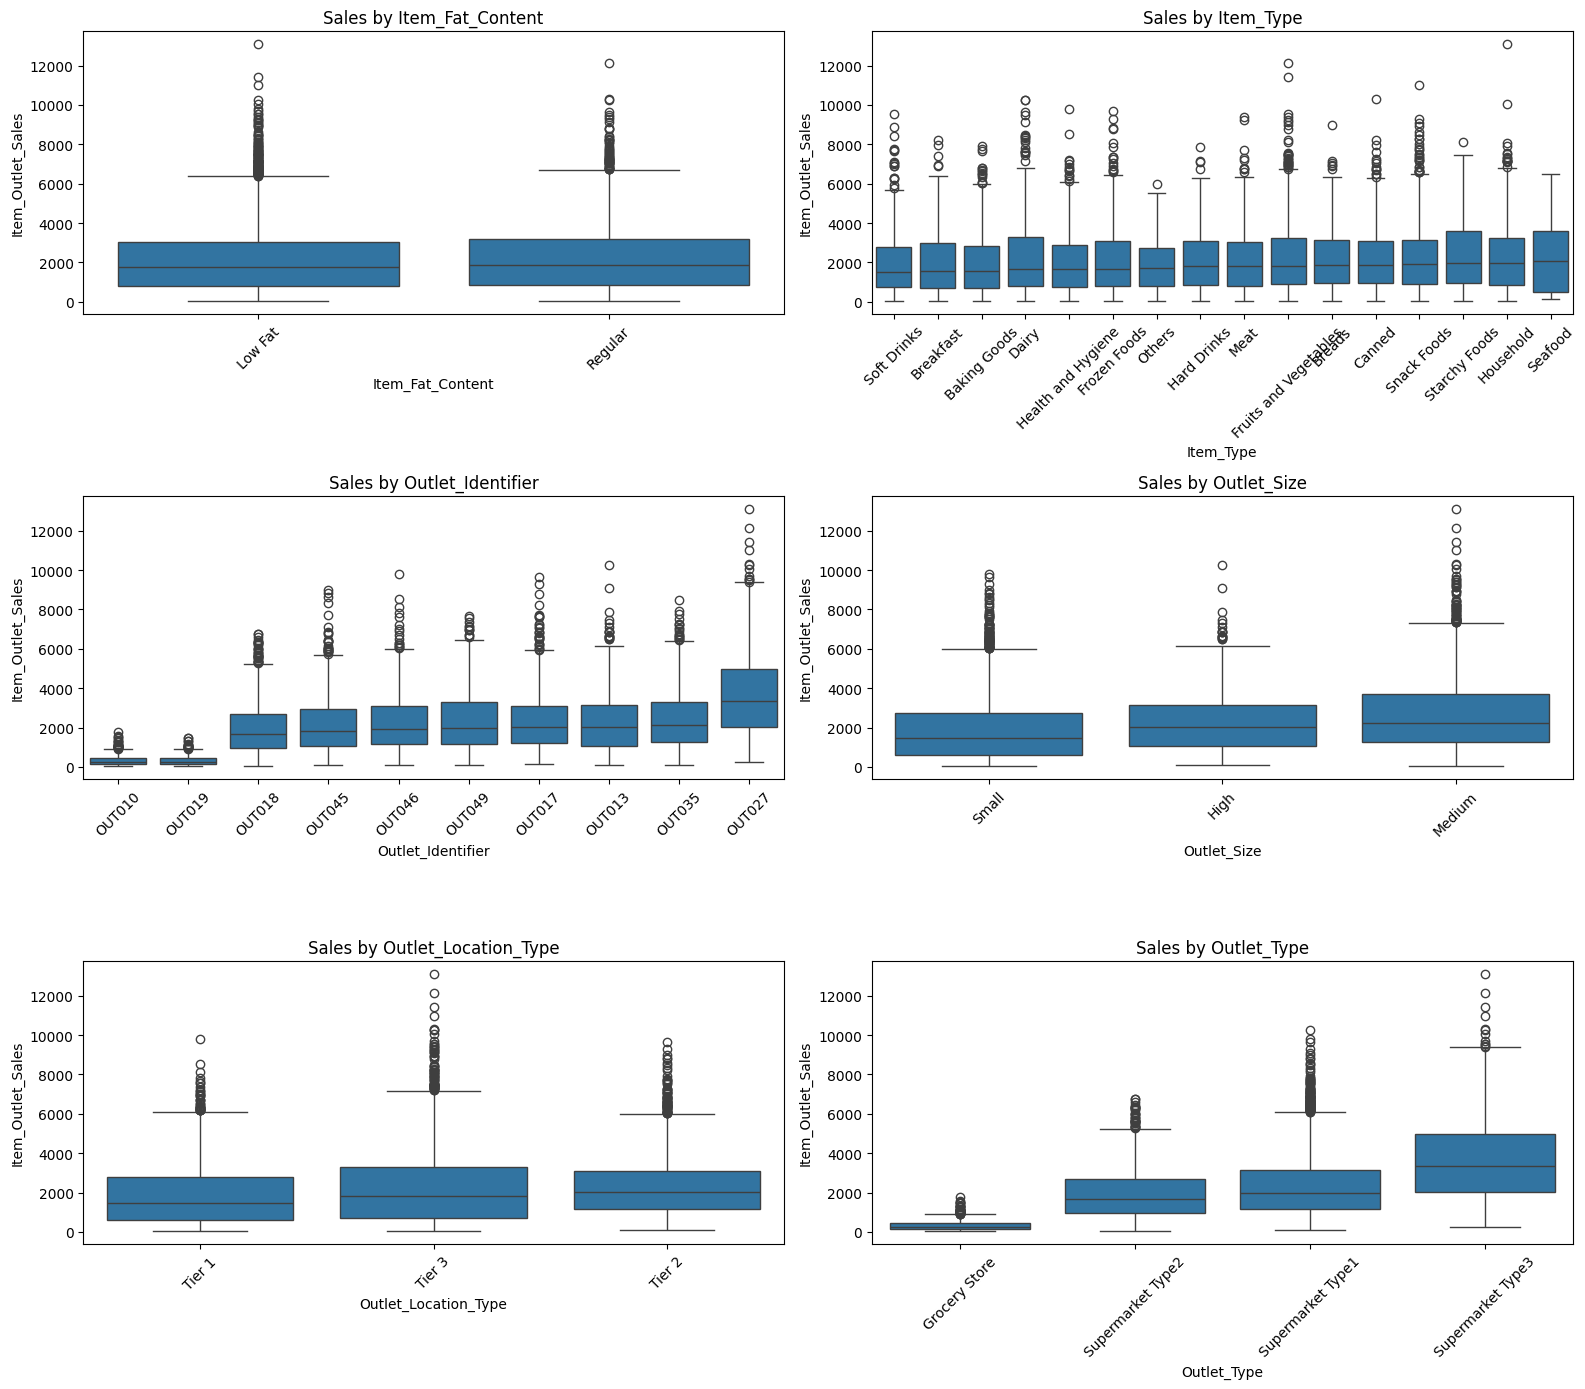

In [24]:
# Compare sales across categorical groups.
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax, col in zip(axes.ravel(), cat_col):
    order = df_train.groupby(col)['Item_Outlet_Sales'].median().sort_values().index
    sns.boxplot(data=df_train, x=col, y='Item_Outlet_Sales', order=order, ax=ax)
    ax.set_title(f'Sales by {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

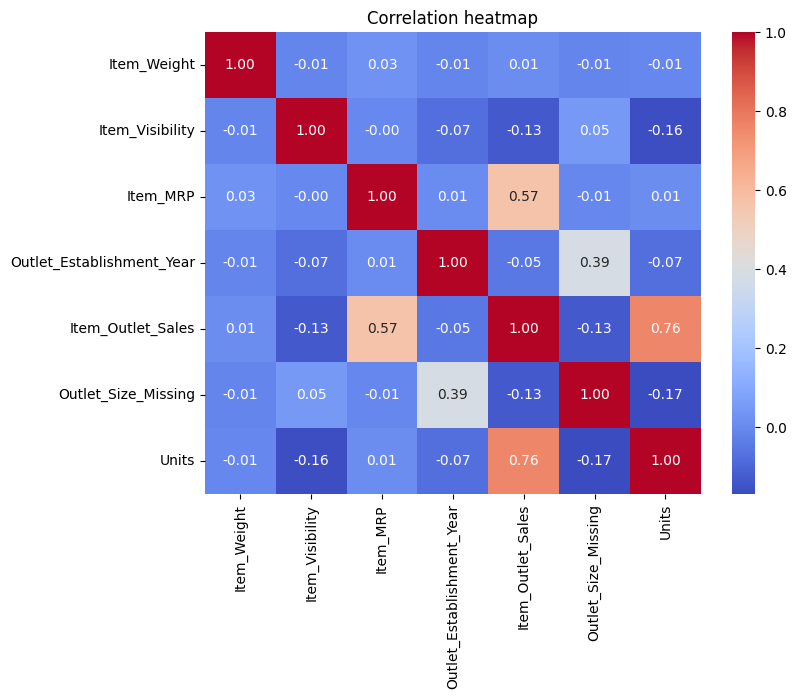

In [25]:
# Correlations between numeric columns
corr = df_train.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

Item_Weight
  Q1=8.7850  Q3=16.8500  IQR=8.0650
  Bounds: [-3.3125, 28.9475]
  Outliers: 0 (0.00%)
  Min=4.5550  Max=21.3500
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


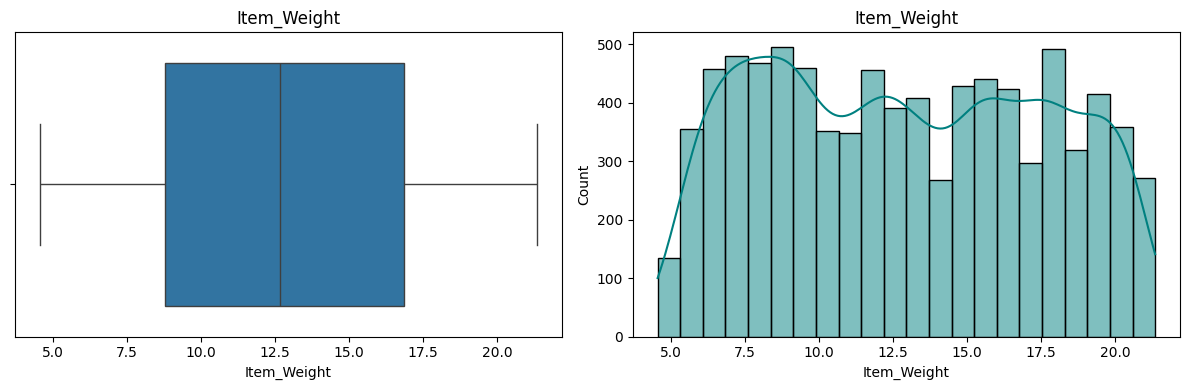

Item_Visibility
  Q1=0.0270  Q3=0.0946  IQR=0.0676
  Bounds: [-0.0744, 0.1960]
  Outliers: 144 (1.69%)
  Min=0.0000  Max=0.3284
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


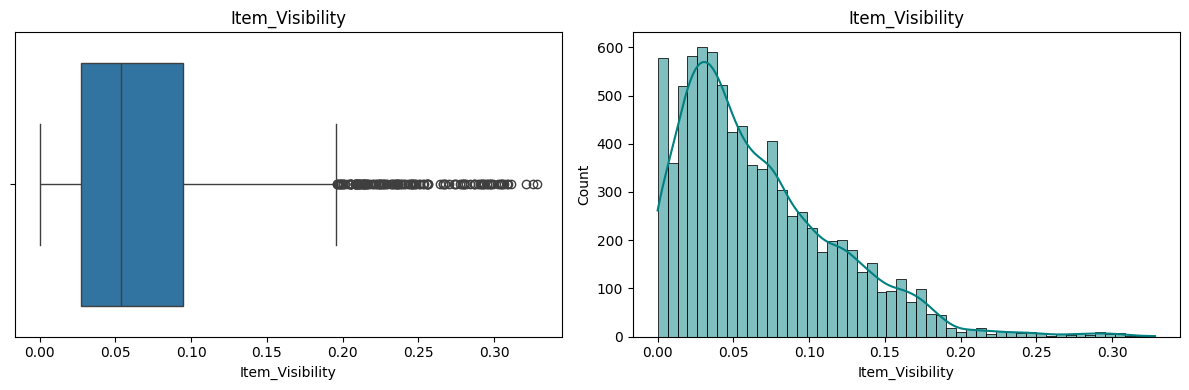

Item_MRP
  Q1=93.8265  Q3=185.6437  IQR=91.8172
  Bounds: [-43.8993, 323.3695]
  Outliers: 0 (0.00%)
  Min=31.2900  Max=266.8884
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)


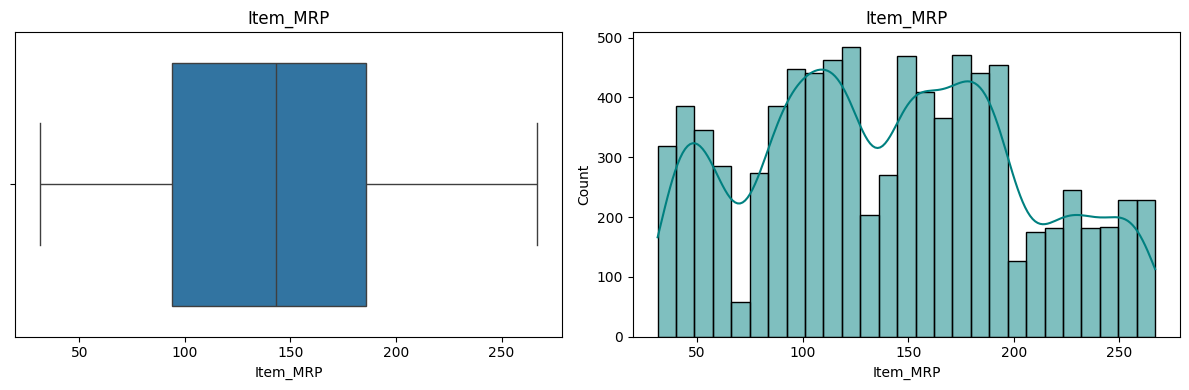

In [26]:
#handling outliers
for col in num_cols:
    Q1 = df_train[col].quantile(0.25)
    Q3 = df_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df_train[col] < lower) | (df_train[col] > upper)).sum()
    pct = (n_out / len(df_train)) * 100
    print(f"{col}")
    print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
    print(f"  Bounds: [{lower:.4f}, {upper:.4f}]")
    print(f"  Outliers: {n_out} ({pct:.2f}%)")
    print(f"  Min={df_train[col].min():.4f}  Max={df_train[col].max():.4f}")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=df_train[col], ax=axes[0])
    axes[0].set_title(col)
    sns.histplot(df_train[col], kde=True, ax=axes[1], color='teal')
    axes[1].set_title(col)
    plt.tight_layout()
    plt.show()

In [27]:
def iqr_outliers(group):
    q1, q3 = group.quantile(0.25), group.quantile(0.75)
    iqr = q3 - q1
    return group[(group < q1 - 1.5 * iqr) | (group > q3 + 1.5 * iqr)]

In [28]:
# Outliers per Item_Type
for col in num_cols:
    print(f"\n{col} — outliers per Item_Type:")
    for t, g in df_train.groupby('Item_Type')[col]:
        out = iqr_outliers(g)
        print(f"  {t}: {len(out)} ({len(out)/len(g)*100:.2f}%)")


Item_Weight — outliers per Item_Type:
  Baking Goods: 0 (0.00%)
  Breads: 0 (0.00%)
  Breakfast: 0 (0.00%)
  Canned: 0 (0.00%)
  Dairy: 0 (0.00%)
  Frozen Foods: 0 (0.00%)
  Fruits and Vegetables: 0 (0.00%)
  Hard Drinks: 0 (0.00%)
  Health and Hygiene: 0 (0.00%)
  Household: 0 (0.00%)
  Meat: 0 (0.00%)
  Others: 0 (0.00%)
  Seafood: 0 (0.00%)
  Snack Foods: 0 (0.00%)
  Soft Drinks: 0 (0.00%)
  Starchy Foods: 0 (0.00%)

Item_Visibility — outliers per Item_Type:
  Baking Goods: 14 (2.16%)
  Breads: 3 (1.20%)
  Breakfast: 3 (2.73%)
  Canned: 6 (0.92%)
  Dairy: 12 (1.76%)
  Frozen Foods: 13 (1.52%)
  Fruits and Vegetables: 21 (1.70%)
  Hard Drinks: 5 (2.34%)
  Health and Hygiene: 18 (3.46%)
  Household: 13 (1.43%)
  Meat: 9 (2.12%)
  Others: 2 (1.18%)
  Seafood: 0 (0.00%)
  Snack Foods: 18 (1.50%)
  Soft Drinks: 5 (1.12%)
  Starchy Foods: 4 (2.70%)

Item_MRP — outliers per Item_Type:
  Baking Goods: 0 (0.00%)
  Breads: 0 (0.00%)
  Breakfast: 0 (0.00%)
  Canned: 0 (0.00%)
  Dairy: 0 (0.00

/tmp/ipykernel_678/1677680162.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Item_Type', y='Item_Weight', order=order, palette='Set2')
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 

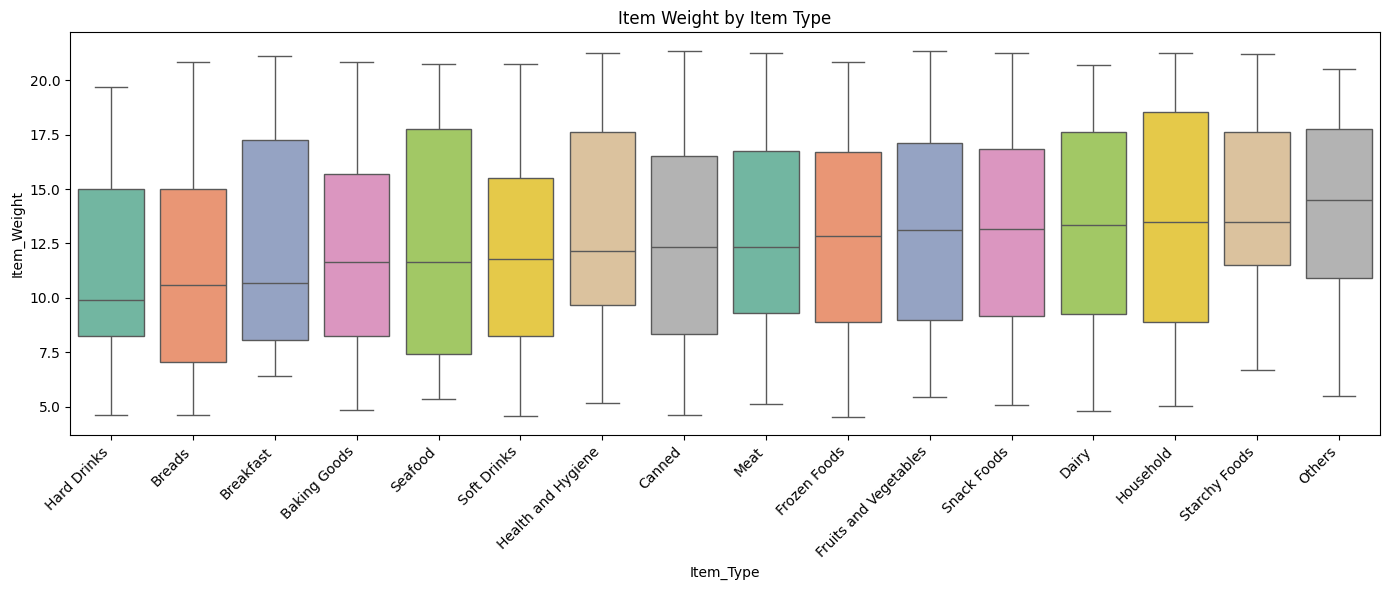

In [29]:
plot_df = df_train[['Item_Type', 'Item_Weight']].dropna() #dropping missing values
order = plot_df.groupby('Item_Type')['Item_Weight'].median().sort_values().index #calculates the median weight for each item type and sorts it in asc
plt.figure(figsize=(14, 6))
sns.boxplot(data=plot_df, x='Item_Type', y='Item_Weight', order=order, palette='Set2')
plt.title('Item Weight by Item Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

/tmp/ipykernel_678/45120294.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Item_Type', y='Item_Visibility', order=order, palette='Set2')
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/root/venv/lib/python3.13/site-packages/seaborn/categorical.py:640: FutureWarning: SeriesGroupBy.grouper is deprecated and will be removed in a future version of pandas.
  positions = grouped.grouper.result_index.to_numpy(dtype=float)
/root/venv/lib/python3.13/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
 [Text(0, 0, 'Meat'),
  Text(1, 0, 'Health and Hygiene'),
  Text(2, 0, 'Household'),
  Text(3, 0, 'Others'),
  Text(4, 0, 'Soft Drinks'),
  Text(5, 0, 'Canned'),
  Text(6, 0, 'Snack Foods'),
  Text(7, 0, 'Fruits and Vegetables'),
  Text(8, 0, 'Seafood'),
  Text(9, 0, 'Breads'),
  Text(10, 0, 'Frozen Foods'),
  Text(11, 0, 'Baking Goods'),
  Text(12, 0, 'Hard Drinks'),
  Text(13, 0, 'Starchy Foods'),
  Text(14, 0, 'Dairy'),
  Text(15, 0, 'Breakfast')])

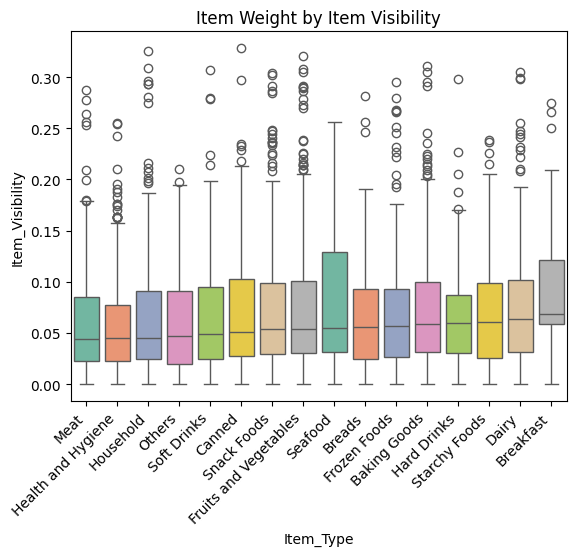

In [30]:
plot_df = df_train[['Item_Type', 'Item_Visibility']].dropna()
order = plot_df.groupby('Item_Type')['Item_Visibility'].median().sort_values().index 
sns.boxplot(data=plot_df, x='Item_Type', y='Item_Visibility', order=order, palette='Set2')
plt.title('Item Weight by Item Visibility')
plt.xticks(rotation=45, ha='right')

                          mean     median          std  count
Outlet_Identifier                                            
OUT010              339.351662   250.3408   271.014855    555
OUT019              340.329723   265.3213   249.979449    528
OUT018             1995.498739  1655.1788  1375.932889    928
OUT045             2192.384798  1834.9448  1462.399658    929
OUT046             2277.844267  1945.8005  1488.405631    930
OUT013             2298.995256  2050.6640  1533.531664    932
OUT017             2340.675263  2005.0567  1550.778025    926
OUT049             2348.354635  1966.1074  1513.289464    930
OUT035             2438.841866  2109.2544  1538.512533    930
OUT027             3694.038558  3364.9532  2127.760054    935
/tmp/ipykernel_678/943387079.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_train, x='Outlet

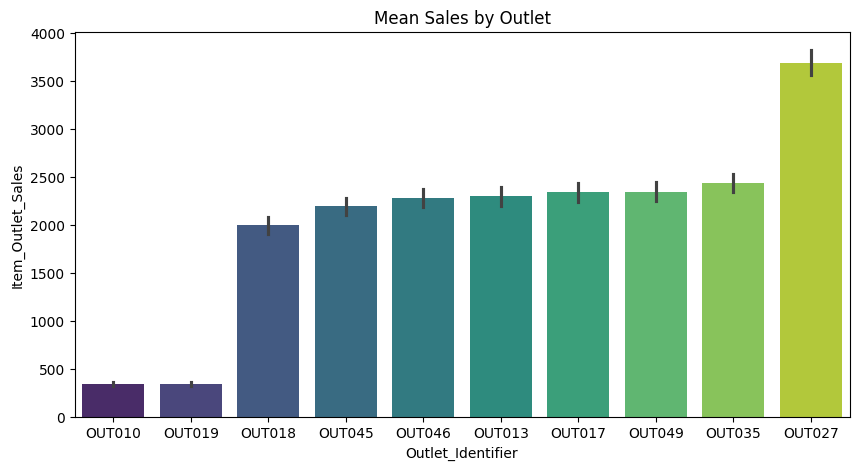

In [31]:
# Mean sales by outlet
store = df_train.groupby('Outlet_Identifier')['Item_Outlet_Sales'].agg(['mean', 'median', 'std', 'count']).sort_values('mean')
print(store)
plt.figure(figsize=(10, 5))
sns.barplot(data=df_train, x='Outlet_Identifier', y='Item_Outlet_Sales',order=store.index, palette='viridis')
plt.title('Mean Sales by Outlet')
plt.show()

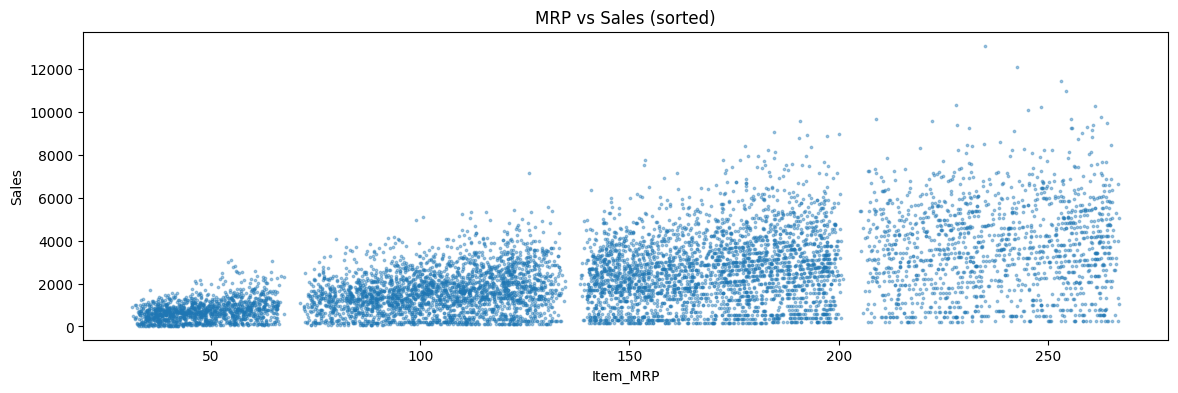

In [32]:
# Sort by MRP to check for step-like sales patterns.
df_sorted = df_train.sort_values('Item_MRP')
plt.figure(figsize=(14, 4))
plt.scatter(df_sorted['Item_MRP'], df_sorted['Item_Outlet_Sales'], s=3, alpha=0.4)
plt.title('MRP vs Sales (sorted)')
plt.xlabel('Item_MRP')
plt.ylabel('Sales')
plt.show()

Item_MRP
(31.288999999999998, 52.796]     633.053399
(52.796, 84.689]                1049.230386
(84.689, 102.133]               1464.349436
(102.133, 118.765]              1673.048215
(118.765, 143.013]              1946.188038
(143.013, 159.433]              2331.467494
(159.433, 177.783]              2620.513780
(177.783, 194.486]              2975.776689
(194.486, 231.2]                3308.933007
(231.2, 266.888]                3811.242140
Name: Item_Outlet_Sales, dtype: float64


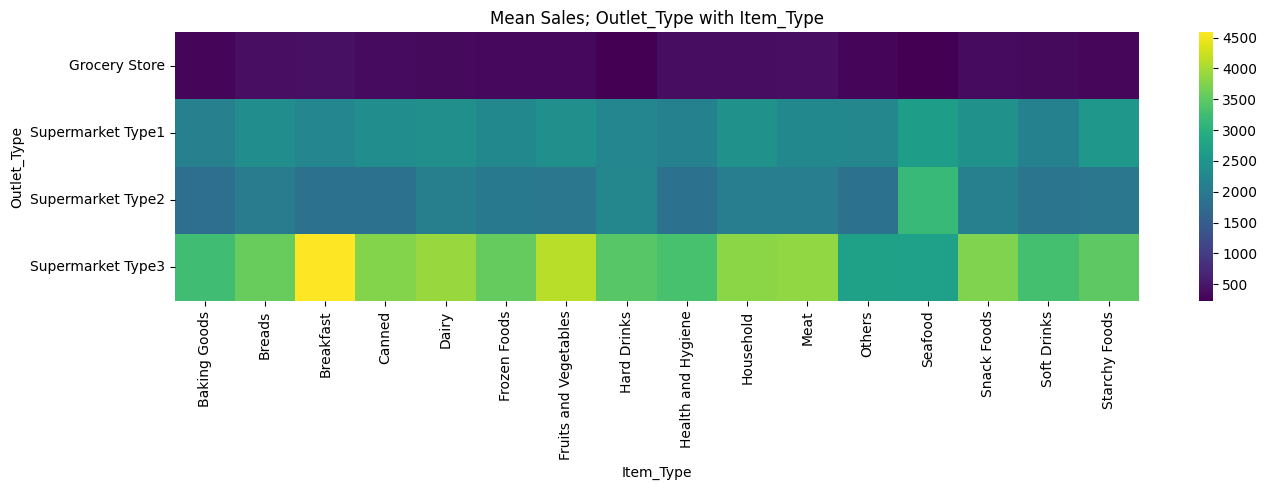

Item_Fat_Content               to 2 unique
Item_Type                      to 16 unique
Outlet_Identifier              to 10 unique
Outlet_Size                    to 3 unique
Outlet_Location_Type           to 3 unique
Outlet_Type                    to 4 unique
Item_Identifier                to 1559 unique
Outlet_Identifier              to 10 unique
Outlet_Establishment_Year      to 9 unique


In [33]:
# Compare average sales across MRP deciles.
mrp_decile = pd.qcut(df_train['Item_MRP'], 10)
print(df_train.groupby(mrp_decile, observed=True)['Item_Outlet_Sales'].mean())
pivot = df_train.pivot_table(
    values='Item_Outlet_Sales',
    index='Outlet_Type', columns='Item_Type',
    aggfunc='mean'
)
plt.figure(figsize=(14, 5))
sns.heatmap(pivot, cmap='viridis', annot=False)
plt.title('Mean Sales; Outlet_Type with Item_Type')
plt.tight_layout()
plt.show()
# Cardinality check — informs which columns need target encoding vs one-hot
for c in cat_col + ['Item_Identifier', 'Outlet_Identifier', 'Outlet_Establishment_Year']:
    print(f"{c:30s} to {df_train[c].nunique()} unique")

In [34]:
# cardinality check for high-cardinality features.
item = df_train.groupby('Item_Identifier')['Item_Outlet_Sales'].agg(['mean', 'count'])
print("Items appearing once:", (item['count'] == 1).sum())
print("Items appearing >5 times:", (item['count'] > 5).sum())
print("Mean-sales range:", round(item['mean'].min(), 2), "to", round(item['mean'].max(), 2))

Items appearing once: 9
Items appearing >5 times: 773
Mean-sales range: 110.97 to 6035.31


In [35]:
import os
os.makedirs("/work/artifacts", exist_ok=True)

df_train.to_parquet("/work/artifacts/df_train_cleaned.parquet", index=False)
df_test.to_parquet("/work/artifacts/df_test_cleaned.parquet", index=False)

# Also save the outlet maps (used later for diagnostics / weighting)
pd.Series(outlet_tr, name="Outlet_Identifier").to_csv(
    "/work/artifacts/outlet_tr.csv", index=False)
pd.Series(outlet_te, name="Outlet_Identifier").to_csv(
    "/work/artifacts/outlet_te.csv", index=False)

print("Saved:", df_train.shape, df_test.shape)

Saved: (8523, 14) (5681, 12)


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=6d372df8-eee0-413a-89a1-c6a537fcecfa' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>